# Student Performance Prediction Using Machine Learning

##  Project Idea

The aim of this project is to use machine learning to predict student performance in mathematics. Students will be classified into 3 categories: "Low, Medium, and High", based on their final mathematics grades.

We will use the Student Performance dataset from the UCI Machine Learning Repository and compare two machine learning algorithms: Decision Tree and K-Nearest Neighbors (KNN).

This project demonstrates how student data can be prepared, used to train machine learning models, and evaluated to compare their prediction accuracy.

## Why Is This Project Useful?

Understanding patterns in student performance may help educators identify areas where additional academic support could be useful. However, model predictions are estimates and should not be used as definitive judgments about individual students.

In [46]:
#importing libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print("Libraries imported successfully!")


Libraries imported successfully!


Data Preparation

 We load the Student Performance dataset from the UCI Machine Learning Repository. We check the dataset for missing values and duplicate records, prepare the input features, and create the target variable using the final grade (G3). Students are classified into three categories: Low (G3 < 10), Medium (10 ≤ G3 < 15), and High (G3 ≥ 15).
 Finally, we separate the features and target and split the data into training and testing sets for model development and evaluation.

In [47]:

df = pd.read_csv("/content/student-mat.csv", sep=";")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Number of rows: 395
Number of columns: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [48]:
#Display the dataset columns


print("Column names in our dataset:")
print(df.columns.tolist())

print("\nFirst five student records:")
display(df.head())


Column names in our dataset:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

First five student records:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [49]:
#Check for missing values


print("Missing values in each column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("Total missing values:", df.isnull().sum().sum())


Missing values in each column:


,Missing Values
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


Total missing values: 0


In [50]:
#Check for duplicate records


print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Dataset shape after cleaning:", df.shape)


Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0
Dataset shape after cleaning: (395, 33)


In [51]:

def categorize_performance(grade):
    if grade < 10:
        return "Low"
    elif grade < 15:
        return "Medium"
    else:
        return "High"


df["performance"] = df["G3"].apply(categorize_performance)

print("Number of students in each performance category:")

display(
    df["performance"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
    .to_frame(name="Number of Students")
)


Number of students in each performance category:


,Number of Students
performance,
Low,130
Medium,192
High,73


In [52]:

X = df.drop(columns=["G3", "performance"])
y = df["performance"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput feature names:")
print(X.columns.tolist())

print("\nTarget categories:")
print(y.unique())


Input features shape: (395, 32)
Target shape: (395,)

Input feature names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Target categories:
['Low' 'Medium' 'High']


In [53]:

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Numerical features:")
print(numeric_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:")
print(categorical_features)


Number of numerical features: 15
Numerical features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Number of categorical features: 17
Categorical features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [54]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts().reindex(["Low", "Medium", "High"]))

print("\nTesting target distribution:")
display(y_test.value_counts().reindex(["Low", "Medium", "High"]))


Training input shape: (316, 32)
Testing input shape: (79, 32)

Training target distribution:


,count
performance,
Low,104
Medium,154
High,58



Testing target distribution:


,count
performance,
Low,26
Medium,38
High,15


In [55]:

from sklearn.base import clone

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Data preprocessing pipeline created successfully!")


Data preprocessing pipeline created successfully!


## 3. Model Building

In this step, we train four machine learning classification models to predict student performance as Low, Medium, or High based on the prepared dataset.

1. **Decision Tree:** Creates a tree of decision rules to classify students based on their features.
2. **K-Nearest Neighbors (KNN):** Predicts a student's performance by comparing their features with those of similar students in the training dataset.
3. **Random Forest:** Combines multiple decision trees to improve prediction accuracy and reduce overfitting compared with a single decision tree.
4. **Gradient Boosting:** Builds decision trees sequentially, with each new tree attempting to correct errors made by the previous trees.

Before training, we preprocess the numerical and categorical features using an appropriate pipeline. We then train all four models on the training dataset and evaluate them using the same test dataset. This allows us to compare their performance and identify which model is most suitable for predicting student performance.

In [56]:

decision_tree_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [57]:

knn_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")


KNN model trained successfully!


In [58]:

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Random Forest model
random_forest_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        random_state=42,
        class_weight="balanced"
    ))
])

# Gradient Boosting model
gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train both models
random_forest_model.fit(X_train, y_train)
gradient_boosting_model.fit(X_train, y_train)

print("Random Forest trained successfully!")
print("Gradient Boosting trained successfully!")


Random Forest trained successfully!
Gradient Boosting trained successfully!


## 4. Evaluation

We evaluate and compare the four trained machine learning models: Decision Tree, K-Nearest Neighbors (KNN), Random Forest, and Gradient Boosting. We use accuracy to measure the percentage of correct predictions on the test dataset. Confusion matrices show the actual and predicted student performance categories and help identify incorrect predictions. We also use classification reports to examine precision, recall, and F1-score. Additionally, we use 5-fold stratified cross-validation to compare the models' average performance and consistency across different data splits.

In [65]:

from sklearn.metrics import accuracy_score
import pandas as pd

# Store all four trained models
models = {
    "Decision Tree": decision_tree_model,
    "KNN": knn_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

# Compare model accuracy
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy (%)", ascending=False
).reset_index(drop=True)

display(results_df)


,Model,Accuracy (%)
0,Random Forest,88.61
1,Gradient Boosting,87.34
2,Decision Tree,84.81
3,KNN,65.82


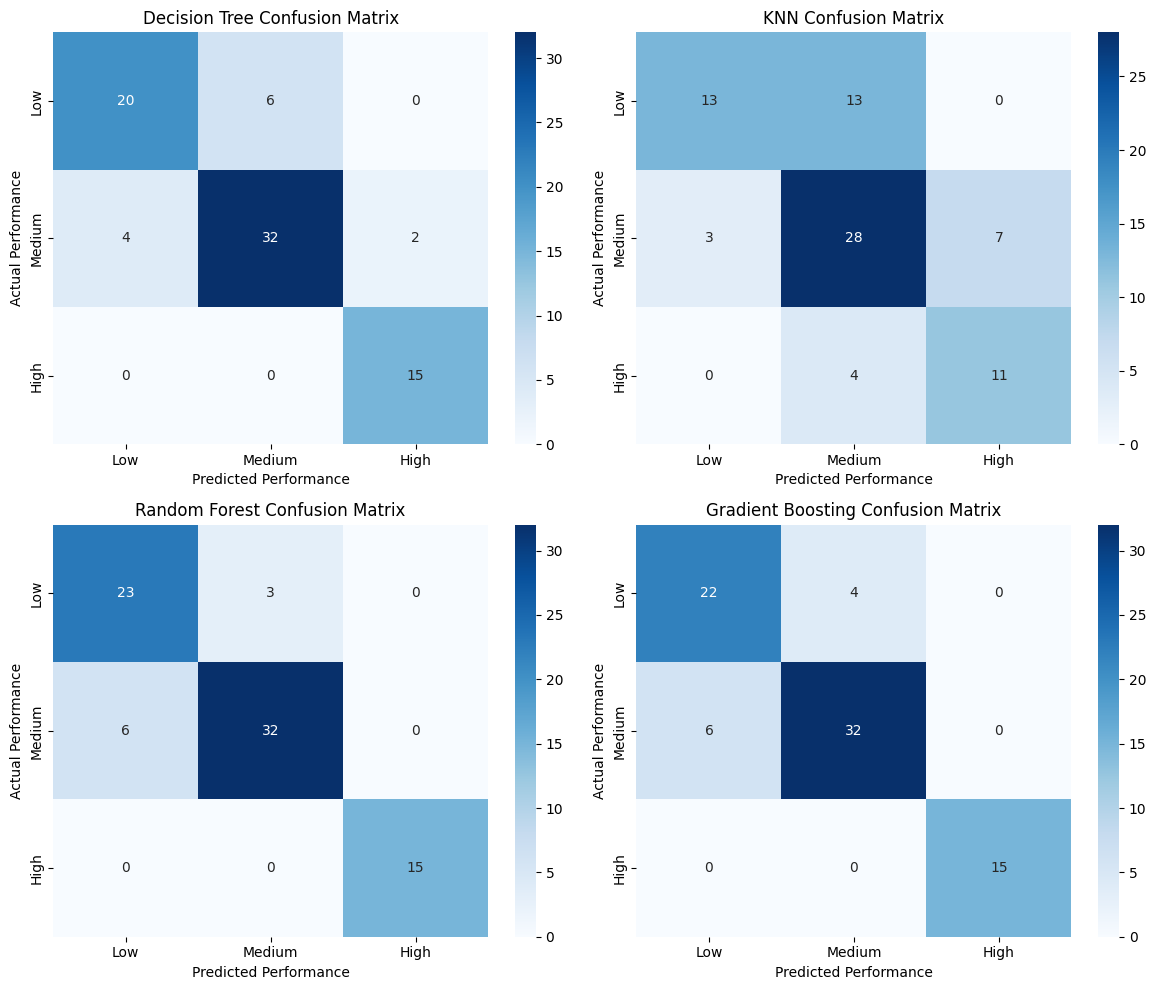

In [66]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test, y_pred, labels=["Low", "Medium", "High"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Low", "Medium", "High"],
        yticklabels=["Low", "Medium", "High"],
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted Performance")
    ax.set_ylabel("Actual Performance")

plt.tight_layout()
plt.show()


In [67]:

from sklearn.metrics import classification_report

for name, model in models.items():
    y_pred = model.predict(X_test)

    print(f"\n{'=' * 50}")
    print(f"Classification Report: {name}")
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    ))



Classification Report: Decision Tree
              precision    recall  f1-score   support

         Low       0.83      0.77      0.80        26
      Medium       0.84      0.84      0.84        38
        High       0.88      1.00      0.94        15

    accuracy                           0.85        79
   macro avg       0.85      0.87      0.86        79
weighted avg       0.85      0.85      0.85        79


Classification Report: KNN
              precision    recall  f1-score   support

         Low       0.81      0.50      0.62        26
      Medium       0.62      0.74      0.67        38
        High       0.61      0.73      0.67        15

    accuracy                           0.66        79
   macro avg       0.68      0.66      0.65        79
weighted avg       0.68      0.66      0.65        79


Classification Report: Random Forest
              precision    recall  f1-score   support

         Low       0.79      0.88      0.84        26
      Medium       0.91  

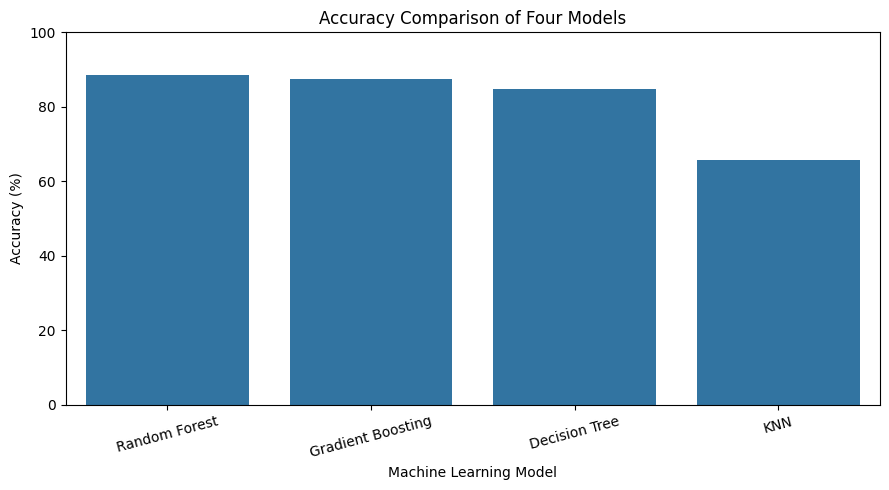

In [68]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Accuracy Comparison of Four Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [59]:

from sklearn.metrics import f1_score

# Collect all four trained models
models = {
    "Decision Tree": decision_tree_model,
    "KNN": knn_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

comparison_results = []

for model_name, model in models.items():
    predictions = model.predict(X_test)

    comparison_results.append({
        "Model": model_name,
        "Accuracy (%)": round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        "Weighted F1-score": round(
            f1_score(y_test, predictions, average="weighted"), 3
        ),
        "Macro F1-score": round(
            f1_score(y_test, predictions, average="macro"), 3
        )
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values(
    by="Macro F1-score", ascending=False
).reset_index(drop=True)

print("COMPARISON OF ALL FOUR MODELS")
display(comparison_df)


COMPARISON OF ALL FOUR MODELS


,Model,Accuracy (%),Weighted F1-score,Macro F1-score
0,Random Forest,88.61,0.887,0.904
1,Gradient Boosting,87.34,0.874,0.893
2,Decision Tree,84.81,0.846,0.860
3,KNN,65.82,0.655,0.653


In [60]:

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1_macro": "f1_macro"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "Mean CV Accuracy (%)": round(
            scores["test_accuracy"].mean() * 100, 2
        ),
        "Accuracy Std (%)": round(
            scores["test_accuracy"].std() * 100, 2
        ),
        "Mean CV Macro F1": round(
            scores["test_f1_macro"].mean(), 3
        )
    })

cv_comparison = pd.DataFrame(cv_results).sort_values(
    "Mean CV Macro F1", ascending=False
).reset_index(drop=True)

print("5-FOLD STRATIFIED CROSS-VALIDATION RESULTS")
display(cv_comparison)


5-FOLD STRATIFIED CROSS-VALIDATION RESULTS


,Model,Mean CV Accuracy (%),Accuracy Std (%),Mean CV Macro F1
0,Gradient Boosting,89.54,3.99,0.901
1,Random Forest,85.75,1.78,0.861
2,Decision Tree,81.95,2.23,0.828
3,KNN,64.86,4.03,0.627


In [61]:


student = X_test.iloc[[0]]

predicted_class = gradient_boosting_model.predict(student)[0]
probabilities = gradient_boosting_model.predict_proba(student)[0]
class_names = gradient_boosting_model.classes_

print("Predicted performance:", predicted_class)
print("\nPredicted probability for each class:")

for class_name, probability in zip(class_names, probabilities):
    print(f"{class_name}: {probability:.1%}")

Predicted performance: Low

Predicted probability for each class:
High: 0.0%
Low: 99.2%
Medium: 0.8%


In [62]:
import pandas as pd
from sklearn.metrics import confusion_matrix


test_predictions = gradient_boosting_model.predict(X_test)
test_probabilities = gradient_boosting_model.predict_proba(X_test)


early_warning_report = X_test.copy()
early_warning_report["Actual_Performance"] = y_test
early_warning_report["Predicted_Performance"] = test_predictions


class_names = list(gradient_boosting_model.classes_)
low_index = class_names.index("Low")

early_warning_report["Low_Performance_Probability"] = (
    test_probabilities[:, low_index]
)


missed_students = early_warning_report[
    (early_warning_report["Actual_Performance"] == "Low") &
    (early_warning_report["Predicted_Performance"] != "Low")
].copy()

print("Total students in test set:", len(X_test))
print("Actual Low-performance students:", (y_test == "Low").sum())
print("Low-performance students missed by the model:", len(missed_students))

display(
    missed_students[
        ["G1", "G2", "absences", "failures",
         "Actual_Performance", "Predicted_Performance",
         "Low_Performance_Probability"]
    ].sort_values("Low_Performance_Probability", ascending=False)
)

Total students in test set: 79
Actual Low-performance students: 26
Low-performance students missed by the model: 4


,G1,G2,absences,failures,Actual_Performance,Predicted_Performance,Low_Performance_Probability
183,9,9,56,0,Low,Medium,0.340096
44,10,10,14,1,Low,Medium,0.048101
341,10,10,0,1,Low,Medium,0.046536
347,10,10,0,0,Low,Medium,0.006368


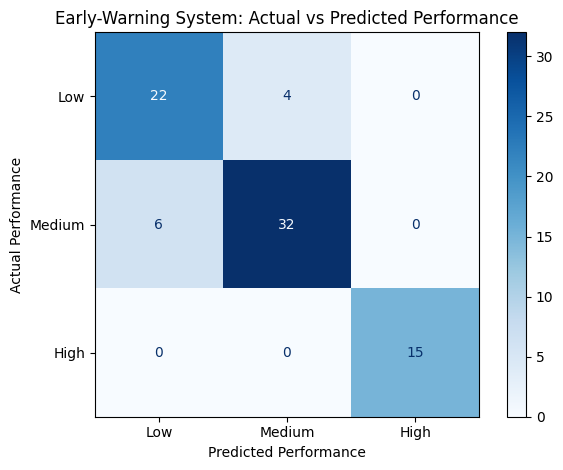

In [63]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=["Low", "Medium", "High"],
    display_labels=["Low", "Medium", "High"],
    cmap="Blues",
    values_format="d"
)

plt.title("Early-Warning System: Actual vs Predicted Performance")
plt.xlabel("Predicted Performance")
plt.ylabel("Actual Performance")
plt.tight_layout()
plt.show()

## 5. Conclusion

In this project, we developed machine learning models to predict student performance by classifying students into Low, Medium, and High final-grade categories. We prepared the dataset by checking for missing values and duplicates, processing numerical and categorical features, and splitting the data into training and testing sets.

We implemented and compared four classification algorithms: Decision Tree, K-Nearest Neighbors (KNN), Random Forest, and Gradient Boosting. We evaluated the models using accuracy, confusion matrices, precision, recall, F1-score, and 5-fold stratified cross-validation.

Random Forest achieved the highest test accuracy of 88.61%, while Gradient Boosting achieved the highest mean cross-validation accuracy of 89.54%. Therefore, Random Forest performed best on the separate test set, whereas Gradient Boosting showed the best average cross-validation performance.

Through this project, we learned how to prepare data, train multiple machine learning models, compare their performance, and interpret evaluation metrics. We also found that earlier grades, particularly G1 and G2, were important predictors of final performance. These predictions could help identify students who may benefit from additional academic support, but they should be used as guidance rather than definitive judgments.